In [1]:
# Make sure "Internet" is turned ON in notebook settings (right sidebar)
!wget -O bangladesh_corn.zip "https://data.mendeley.com/public-api/zip/vy629dngm8/download/1"
!unzip -q bangladesh_corn.zip -d /kaggle/working/bangladesh_corn
!ls /kaggle/working/bangladesh_corn

--2026-06-26 07:29:55--  https://data.mendeley.com/public-api/zip/vy629dngm8/download/1
Resolving data.mendeley.com (data.mendeley.com)... 162.159.133.86, 162.159.130.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.133.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/vy629dngm8-1.zip?X-Amz-Security-Token=IQoJb3JpZ2luX2VjEJf%2F%2F%2F%2F%2F%2F%2F%2F%2F%2FwEaCWV1LXdlc3QtMSJHMEUCIQCwarZdQ2R4c21Zajurb7TdgjG6DtMa32YXxc0ac%2Fd2ZQIgKh5m2r1Gl77u7%2Bq8zPqSy2LRXeAUgz%2BYUBOp6V5pxhQqjAUIYBAEGgwzNjcxNDczODM4MjUiDEUVVXmDsADFgGHk0CrpBAAzhOtNG6lhGzU%2FEnbaTcwYbzAWHyXeQ%2BmepC05jBiSFirPTFBXfqU%2BTCcm7YZ1rsf0RtAuFYEoo%2Ffl0qNnOJlKRecsstlqmtqZKHOJ%2Fk3tvuUpzXMfeTFGp9ccxIUpvp931K1NjYX4rYY2oqQnYNW%2B%2FcNfgeEwgOmkqo2qKPRapkdHryaWnOzO3j6e6atazvgW3b58bPSHX8r6j%2BNm%2FHz2oPT1uFhE6eK8NnOgD%2BvAjQ5N2n%2BKjQQ6tgZo8zWPaDGeE4iFsTpeJrJDgxC0XXXs7jUHq0SxVuxm6NT0L25rFwmNbXHui4nLuZ4arax%2FK0Ugr%2FLiYIa1b9

In [2]:
# Clean start to avoid interactive prompts
!rm -rf /kaggle/working/bangladesh_corn
!unzip -oq bangladesh_corn.zip -d /kaggle/working/bangladesh_corn

# Find and extract the inner zip
!find /kaggle/working/bangladesh_corn -name "*.zip"

/kaggle/working/bangladesh_corn/Seasonal Corn Leaf Disease Dataset A Multi-Year Collection for Robust Analysis/Corn leaf disease dataset.zip


In [3]:
!unzip -oq "/kaggle/working/bangladesh_corn/Seasonal Corn Leaf Disease Dataset A Multi-Year Collection for Robust Analysis/Corn leaf disease dataset.zip" -d /kaggle/working/bangladesh_corn_final

!find /kaggle/working/bangladesh_corn_final -maxdepth 3 -type d

/kaggle/working/bangladesh_corn_final
/kaggle/working/bangladesh_corn_final/Final corn dataset
/kaggle/working/bangladesh_corn_final/Final corn dataset/Gray_leaf_spot
/kaggle/working/bangladesh_corn_final/Final corn dataset/Common_rust
/kaggle/working/bangladesh_corn_final/Final corn dataset/Bacterial Leaf Streak
/kaggle/working/bangladesh_corn_final/Final corn dataset/Healthy
/kaggle/working/bangladesh_corn_final/Final corn dataset/Maize Chlorotic Mottle Virus


In [4]:
!find /kaggle/input/datasets/irakozekelly/crop-pest-and-disease-dataset -maxdepth 4 -type d | grep -i maize

/kaggle/input/datasets/irakozekelly/crop-pest-and-disease-dataset/Dataset for Crop Pest and Disease Detection/CCMT Dataset-Augmented/Maize
/kaggle/input/datasets/irakozekelly/crop-pest-and-disease-dataset/Dataset for Crop Pest and Disease Detection/CCMT Dataset-Augmented/Maize/test_set
/kaggle/input/datasets/irakozekelly/crop-pest-and-disease-dataset/Dataset for Crop Pest and Disease Detection/CCMT Dataset-Augmented/Maize/train_set
/kaggle/input/datasets/irakozekelly/crop-pest-and-disease-dataset/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize


In [5]:
!ls "/kaggle/input/datasets/irakozekelly/crop-pest-and-disease-dataset/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize"

'fall armyworm'   healthy	'leaf blight'  'streak virus'
 grasshoper	 'leaf beetle'	'leaf spot'


In [6]:
import shutil
from pathlib import Path

# Source paths
bangladesh_root = Path("/kaggle/working/bangladesh_corn_final/Final corn dataset")
ccmt_raw_maize = Path("/kaggle/input/datasets/irakozekelly/crop-pest-and-disease-dataset/"
                       "Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize")

# Destination
final_dir = Path("/kaggle/working/combined_corn_dataset")
final_dir.mkdir(parents=True, exist_ok=True)

# Map: final class name -> [(source folder, filename prefix), ...]
class_map = {
    "Healthy": [
        (bangladesh_root / "Healthy", "bd"),
        (ccmt_raw_maize / "healthy", "ccmt"),
    ],
    "Bacterial_Leaf_Streak": [(bangladesh_root / "Bacterial Leaf Streak", "bd")],
    "Common_rust":           [(bangladesh_root / "Common_rust", "bd")],
    "Gray_leaf_spot":        [(bangladesh_root / "Gray_leaf_spot", "bd")],
    "Maize_Chlorotic_Mottle_Virus": [(bangladesh_root / "Maize Chlorotic Mottle Virus", "bd")],
    "Leaf_blight":  [(ccmt_raw_maize / "leaf blight", "ccmt")],
    "Leaf_spot":    [(ccmt_raw_maize / "leaf spot", "ccmt")],
    "Streak_virus": [(ccmt_raw_maize / "streak virus", "ccmt")],
}

# Pest folders we're deliberately skipping: 'fall armyworm', 'grasshoper', 'leaf beetle'

for class_name, sources in class_map.items():
    dest_dir = final_dir / class_name
    dest_dir.mkdir(parents=True, exist_ok=True)
    count = 0
    for src_dir, prefix in sources:
        if not src_dir.exists():
            print(f"⚠️  Not found: {src_dir}")
            continue
        for f in src_dir.iterdir():
            if f.is_file():
                shutil.copy(f, dest_dir / f"{prefix}_{f.name}")
                count += 1
    print(f"{class_name}: {count} images")

print("\n✅ Final combined dataset:")
total = 0
for d in sorted(final_dir.iterdir()):
    n = len(list(d.iterdir()))
    total += n
    print(f"  {d.name}: {n}")
print(f"\nTotal: {total} images across {len(class_map)} classes")

Healthy: 1246 images
Bacterial_Leaf_Streak: 190 images
Common_rust: 129 images
Gray_leaf_spot: 1497 images
Maize_Chlorotic_Mottle_Virus: 89 images
Leaf_blight: 1006 images
Leaf_spot: 1259 images
Streak_virus: 979 images

✅ Final combined dataset:
  Bacterial_Leaf_Streak: 190
  Common_rust: 129
  Gray_leaf_spot: 1497
  Healthy: 1246
  Leaf_blight: 1006
  Leaf_spot: 1259
  Maize_Chlorotic_Mottle_Virus: 89
  Streak_virus: 979

Total: 6395 images across 8 classes


In [7]:
import shutil

# Remove the half-finished split attempt
shutil.rmtree("/kaggle/working/corn_split", ignore_errors=True)

# Remove the original zip (already extracted, no longer needed)
import os
if os.path.exists("/kaggle/working/bangladesh_corn.zip"):
    os.remove("/kaggle/working/bangladesh_corn.zip")

# Remove the raw nested-zip extraction folder (we already pulled what we needed into bangladesh_corn_final)
shutil.rmtree("/kaggle/working/bangladesh_corn", ignore_errors=True)

# Check how much space we freed
!df -h /kaggle/working

Filesystem      Size  Used Avail Use% Mounted on
/dev/loop1       20G  9.2G   11G  48% /kaggle/working


In [8]:
import random
from pathlib import Path

random.seed(42)
source_dir = Path("/kaggle/working/combined_corn_dataset")
split_dir = Path("/kaggle/working/corn_split")

splits = {"train": 0.70, "val": 0.15, "test": 0.15}

for class_dir in sorted(source_dir.iterdir()):
    if not class_dir.is_dir():
        continue
    files = list(class_dir.iterdir())
    random.shuffle(files)

    n = len(files)
    n_train = int(n * splits["train"])
    n_val = int(n * splits["val"])

    split_files = {
        "train": files[:n_train],
        "val": files[n_train:n_train + n_val],
        "test": files[n_train + n_val:],
    }

    for split_name, file_list in split_files.items():
        dest = split_dir / split_name / class_dir.name
        dest.mkdir(parents=True, exist_ok=True)
        for f in file_list:
            link_path = dest / f.name
            if not link_path.exists():
                os.symlink(f.resolve(), link_path)

    print(f"{class_dir.name}: train={len(split_files['train'])}, "
          f"val={len(split_files['val'])}, test={len(split_files['test'])}")

Bacterial_Leaf_Streak: train=133, val=28, test=29
Common_rust: train=90, val=19, test=20
Gray_leaf_spot: train=1047, val=224, test=226
Healthy: train=872, val=186, test=188
Leaf_blight: train=704, val=150, test=152
Leaf_spot: train=881, val=188, test=190
Maize_Chlorotic_Mottle_Virus: train=62, val=13, test=14
Streak_virus: train=685, val=146, test=148


In [9]:
from pathlib import Path
from PIL import Image
import os

split_dir = Path("/kaggle/working/corn_split")
bad_files = []

for split in ["train", "val", "test"]:
    for class_dir in (split_dir / split).iterdir():
        if not class_dir.is_dir():
            continue
        for f in class_dir.iterdir():
            try:
                img = Image.open(f)
                img.verify()  # checks file integrity without fully decoding
                # Re-open and force a full decode (verify() alone misses some truncation issues)
                img = Image.open(f)
                img.load()
            except Exception as e:
                bad_files.append(f)

print(f"Found {len(bad_files)} corrupted images")
for f in bad_files[:20]:  # preview first 20
    print(f)

Found 54 corrupted images
/kaggle/working/corn_split/train/Streak_virus/ccmt_streak virus118_.jpg
/kaggle/working/corn_split/train/Streak_virus/ccmt_streak virus421_.jpg
/kaggle/working/corn_split/train/Streak_virus/ccmt_streak virus774_.jpg
/kaggle/working/corn_split/train/Streak_virus/ccmt_streak virus626_.jpg
/kaggle/working/corn_split/train/Streak_virus/ccmt_streak virus486_.jpg
/kaggle/working/corn_split/train/Streak_virus/ccmt_streak virus485_.jpg
/kaggle/working/corn_split/train/Streak_virus/ccmt_streak virus997_.jpg
/kaggle/working/corn_split/train/Streak_virus/ccmt_streak virus422_.jpg
/kaggle/working/corn_split/train/Streak_virus/ccmt_streak virus701_.jpg
/kaggle/working/corn_split/train/Streak_virus/ccmt_streak virus998_.jpg
/kaggle/working/corn_split/train/Streak_virus/ccmt_streak virus773_.jpg
/kaggle/working/corn_split/train/Leaf_blight/ccmt_leaf blight666_.jpg
/kaggle/working/corn_split/train/Leaf_blight/ccmt_leaf blight667_.jpg
/kaggle/working/corn_split/train/Leaf_blig

In [10]:
removed = 0
for f in bad_files:
    try:
        # f is a symlink — remove the symlink itself, not the original file
        f.unlink()
        removed += 1
    except Exception as e:
        print(f"Could not remove {f}: {e}")

print(f"Removed {removed} corrupted symlinks/files")

Removed 54 corrupted symlinks/files


In [11]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import numpy as np, os, json
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
IMG_SIZE   = (384, 384)
BATCH_SIZE = 32
AUTOTUNE   = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/kaggle/working/corn_split/train",
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="categorical"
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    "/kaggle/working/corn_split/val",
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="categorical"
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

# ── Preprocessing (no augmentation — already augmented) ──
def prep_train(img, lbl): return preprocess_input(img), lbl
def prep_val(img, lbl):   return preprocess_input(img), lbl

train_ds_p = train_ds.map(prep_train, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds_p   = val_ds.map(prep_val,     num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# ── Class weights ─────────────────────────────────────────
from sklearn.utils.class_weight import compute_class_weight
labels_flat = []
for i, cls in enumerate(class_names):
    cls_dir = os.path.join("/kaggle/working/corn_split/train", cls)
    n = len([f for f in os.listdir(cls_dir) if f.lower().endswith((".jpg",".jpeg",".png"))])
    labels_flat.extend([i] * n)
labels_flat = np.array(labels_flat)
cw = compute_class_weight("balanced", classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = {i: w for i, w in enumerate(cw)}
print("\nClass weights:")
for i, cls in enumerate(class_names):
    print(f"  {cls}: {class_weight_dict[i]:.3f}")

# ── Build model ───────────────────────────────────────────
base = EfficientNetV2S(include_top=False, weights="imagenet", input_shape=(384,384,3))
base.trainable = False

inputs  = tf.keras.Input(shape=(384,384,3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = models.Model(inputs, outputs)

# ── Callbacks ─────────────────────────────────────────────
callbacks = [
    EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    ModelCheckpoint("/kaggle/working/best_corn_model.keras", monitor="val_accuracy", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    tf.keras.callbacks.BackupAndRestore("/kaggle/working/corn_backup/")
]

2026-06-26 07:37:53.465624: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1782459473.644743      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782459473.694878      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782459474.113068      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782459474.113104      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782459474.113107      58 computation_placer.cc:177] computation placer alr

Found 4436 files belonging to 8 classes.


I0000 00:00:1782459488.878458      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1782459488.884248      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 945 files belonging to 8 classes.
Classes: ['Bacterial_Leaf_Streak', 'Common_rust', 'Gray_leaf_spot', 'Healthy', 'Leaf_blight', 'Leaf_spot', 'Maize_Chlorotic_Mottle_Virus', 'Streak_virus']
Number of classes: 8

Class weights:
  Bacterial_Leaf_Streak: 4.169
  Common_rust: 6.161
  Gray_leaf_spot: 0.530
  Healthy: 0.639
  Leaf_blight: 0.798
  Leaf_spot: 0.640
  Maize_Chlorotic_Mottle_Virus: 8.944
  Streak_virus: 0.823
82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [12]:
# ── PHASE 1: frozen base ──────────────────────────────────
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("=== PHASE 1: Frozen base (lr=1e-3) ===")
history = model.fit(train_ds, validation_data=val_ds, epochs=10,
                    class_weight=class_weight_dict, callbacks=callbacks)
print(f"✅ Phase 1 best: {max(history.history['val_accuracy'])*100:.2f}%")

=== PHASE 1: Frozen base (lr=1e-3) ===
Epoch 1/10


I0000 00:00:1782459516.959551     149 service.cc:152] XLA service 0x7cff7801d600 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1782459516.959592     149 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1782459516.959607     149 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1782459522.651886     149 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-06-26 07:38:54.199490: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:38:54.368876: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:38:55.523732: E external/local_xl

138/139 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - accuracy: 0.4222 - loss: 1.7416

2026-06-26 07:40:08.166903: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:40:08.320645: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:40:09.352777: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:40:09.512917: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:40:11.078193: E external/local_xla/xla/stream_

139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 530ms/step - accuracy: 0.4231 - loss: 1.7377

2026-06-26 07:40:57.879465: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:40:58.029700: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:40:59.001503: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:40:59.157760: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:41:00.723668: E external/local_xla/xla/stream_

139/139 ━━━━━━━━━━━━━━━━━━━━ 174s 828ms/step - accuracy: 0.5460 - loss: 1.2037 - val_accuracy: 0.7619 - val_loss: 1.0266 - learning_rate: 0.0010
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 54s 389ms/step - accuracy: 0.7137 - loss: 0.6642 - val_accuracy: 0.8074 - val_loss: 0.6255 - learning_rate: 0.0010
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 54s 389ms/step - accuracy: 0.7617 - loss: 0.5246 - val_accuracy: 0.8138 - val_loss: 0.5106 - learning_rate: 0.0010
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 54s 386ms/step - accuracy: 0.7710 - loss: 0.4726 - val_accuracy: 0.8222 - val_loss: 0.4674 - learning_rate: 0.0010
Epoch 5/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 54s 387ms/step - accuracy: 0.8003 - loss: 0.4182 - val_accuracy: 0.8349 - val_loss: 0.4336 - learning_rate: 0.0010
Epoch 6/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 54s 388ms/step - accuracy: 0.8082 - loss: 0.4017 - val_accuracy: 0.8381 - val_loss: 0.4477 - learning_rate: 0.0010
Epoch 7/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 82s 386ms/step - accuracy: 0.8064 - loss

In [14]:

# ── PHASE 2: full unfreeze ────────────────────────────────
base.trainable = True
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 2: Full fine-tune (lr=1e-4) ===")
history_fine = model.fit(train_ds, validation_data=val_ds, epochs=10,
                         class_weight=class_weight_dict, callbacks=callbacks)
print(f"✅ Phase 2 best: {max(history_fine.history['val_accuracy'])*100:.2f}%")


=== PHASE 2: Full fine-tune (lr=1e-4) ===
Epoch 1/10


2026-06-26 07:51:50.472988: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:51:50.661798: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:51:55.455941: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:51:55.633923: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:51:57.826322: E external/local_xla/xla/stream_

138/139 ━━━━━━━━━━━━━━━━━━━━ 0s 914ms/step - accuracy: 0.6908 - loss: 0.8488

2026-06-26 07:55:24.396787: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:55:24.561008: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:55:28.504062: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:55:28.677112: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-26 07:55:30.159279: E external/local_xla/xla/stream_

139/139 ━━━━━━━━━━━━━━━━━━━━ 413s 2s/step - accuracy: 0.7507 - loss: 0.5951 - val_accuracy: 0.8497 - val_loss: 0.4224 - learning_rate: 1.0000e-04
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 138s 993ms/step - accuracy: 0.8713 - loss: 0.2597 - val_accuracy: 0.8561 - val_loss: 0.3944 - learning_rate: 1.0000e-04
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.8990 - loss: 0.1893 - val_accuracy: 0.8709 - val_loss: 0.3725 - learning_rate: 3.0000e-05
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 138s 988ms/step - accuracy: 0.9186 - loss: 0.1567 - val_accuracy: 0.8667 - val_loss: 0.3805 - learning_rate: 3.0000e-05
Epoch 5/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 138s 987ms/step - accuracy: 0.9288 - loss: 0.1317 - val_accuracy: 0.8709 - val_loss: 0.3874 - learning_rate: 3.0000e-05
Epoch 6/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.9391 - loss: 0.1152 - val_accuracy: 0.8741 - val_loss: 0.3830 - learning_rate: 9.0000e-06
Epoch 7/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 138s 990ms/step - ac

In [15]:
# ── PHASE 3: lower LR ────────────────────────────────────
model.compile(optimizer=tf.keras.optimizers.Adam(5e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 3: Full fine-tune (lr=5e-5) ===")
history_phase3 = model.fit(train_ds, validation_data=val_ds, epochs=15,
                            class_weight=class_weight_dict, callbacks=callbacks)
print(f"✅ Phase 3 best: {max(history_phase3.history['val_accuracy'])*100:.2f}%")



=== PHASE 3: Full fine-tune (lr=5e-5) ===
Epoch 1/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 390s 2s/step - accuracy: 0.9227 - loss: 0.1545 - val_accuracy: 0.8815 - val_loss: 0.4126 - learning_rate: 5.0000e-05
Epoch 2/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - accuracy: 0.9376 - loss: 0.1235 - val_accuracy: 0.8772 - val_loss: 0.4563 - learning_rate: 5.0000e-05
Epoch 3/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9513 - loss: 0.0976 - val_accuracy: 0.8847 - val_loss: 0.4331 - learning_rate: 1.5000e-05
Epoch 4/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 139s 996ms/step - accuracy: 0.9583 - loss: 0.0792 - val_accuracy: 0.8847 - val_loss: 0.4416 - learning_rate: 1.5000e-05
Epoch 5/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 138s 992ms/step - accuracy: 0.9619 - loss: 0.0689 - val_accuracy: 0.8794 - val_loss: 0.4510 - learning_rate: 4.5000e-06
Epoch 6/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 138s 988ms/step - accuracy: 0.9621 - loss: 0.0674 - val_accuracy: 0.8836 - val_loss: 0.4539 - learning_rate: 4.5000e-06
✅ Phas

In [16]:
# ── PHASE 4: polish ───────────────────────────────────────
model.load_weights("/kaggle/working/best_corn_model.keras")
callbacks[0] = EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 4: Polish (lr=1e-5, patience=5) ===")
history_phase4 = model.fit(train_ds, validation_data=val_ds, epochs=15,
                            class_weight=class_weight_dict, callbacks=callbacks)
print(f"✅ Phase 4 best: {max(history_phase4.history['val_accuracy'])*100:.2f}%")


=== PHASE 4: Polish (lr=1e-5, patience=5) ===
Epoch 1/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 387s 2s/step - accuracy: 0.9563 - loss: 0.0815 - val_accuracy: 0.8815 - val_loss: 0.4504 - learning_rate: 1.0000e-05
Epoch 2/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.9619 - loss: 0.0712 - val_accuracy: 0.8857 - val_loss: 0.4471 - learning_rate: 1.0000e-05
Epoch 3/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 138s 994ms/step - accuracy: 0.9603 - loss: 0.0739 - val_accuracy: 0.8836 - val_loss: 0.4482 - learning_rate: 3.0000e-06
Epoch 4/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 139s 996ms/step - accuracy: 0.9606 - loss: 0.0710 - val_accuracy: 0.8815 - val_loss: 0.4527 - learning_rate: 3.0000e-06
Epoch 5/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 139s 996ms/step - accuracy: 0.9621 - loss: 0.0697 - val_accuracy: 0.8804 - val_loss: 0.4533 - learning_rate: 9.0000e-07
Epoch 6/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 137s 985ms/step - accuracy: 0.9651 - loss: 0.0659 - val_accuracy: 0.8836 - val_loss: 0.4583 - learning_rate: 9.0000e-07

In [17]:
model.save("/kaggle/working/corn_final.keras")
print(f"\n🎯 Final: {max(history_phase4.history['val_accuracy'])*100:.2f}%")


🎯 Final: 88.57%



=== Classification Report ===
                              precision    recall  f1-score   support

       Bacterial_Leaf_Streak     1.0000    1.0000    1.0000        28
                 Common_rust     1.0000    1.0000    1.0000        19
              Gray_leaf_spot     0.9955    0.9777    0.9865       224
                     Healthy     0.9427    0.9731    0.9577       186
                 Leaf_blight     0.7571    0.7260    0.7413       146
                   Leaf_spot     0.7551    0.7957    0.7749       186
Maize_Chlorotic_Mottle_Virus     1.0000    1.0000    1.0000        13
                Streak_virus     0.8978    0.8601    0.8786       143

                    accuracy                         0.8857       945
                   macro avg     0.9185    0.9166    0.9174       945
                weighted avg     0.8865    0.8857    0.8858       945



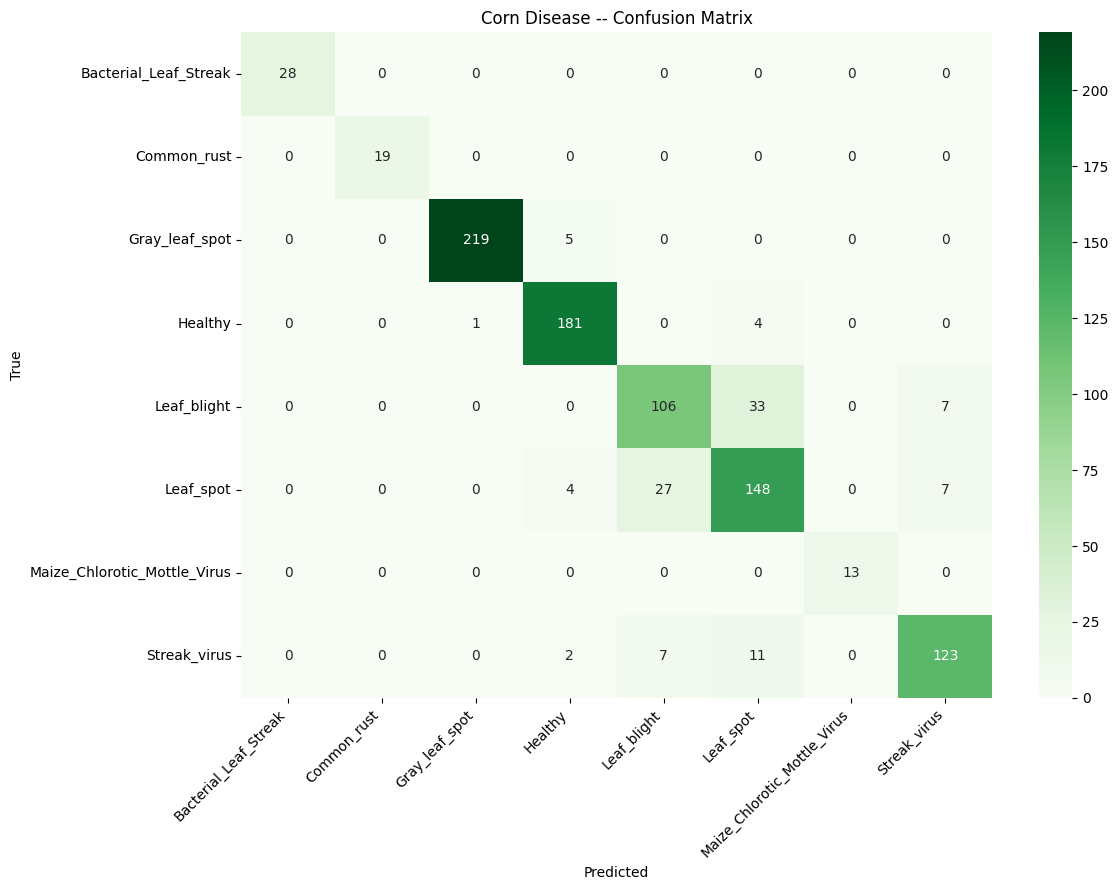

In [18]:
# ── Evaluation ────────────────────────────────────────────
y_true, y_pred = [], []
for imgs, lbls in val_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Corn Disease -- Confusion Matrix")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig("/kaggle/working/corn_confusion_matrix.png", dpi=150)
plt.show()

In [19]:
# ── Class map ─────────────────────────────────────────────
DISEASE_NAMES = {
    "Bacterial_Leaf_Streak"       : "Bacterial Leaf Streak",
    "Common_rust"                 : "Common Rust",
    "Gray_leaf_spot"              : "Gray Leaf Spot",
    "Healthy"                     : "Healthy",
    "Leaf_blight"                 : "Leaf Blight",
    "Leaf_spot"                   : "Leaf Spot",
    "Maize_Chlorotic_Mottle_Virus": "Maize Chlorotic Mottle Virus",
    "Streak_virus"                : "Streak Virus",
}

corn_class_map = {}
production_class_names = []
for cls in class_names:
    key = "corn__" + cls.lower()
    production_class_names.append(key)
    corn_class_map[key] = {"crop": "Corn", "disease": DISEASE_NAMES.get(cls, cls)}

with open("/kaggle/working/corn_class_map.json", "w") as f:
    json.dump(corn_class_map, f, indent=2)
with open("/kaggle/working/corn_class_names.json", "w") as f:
    json.dump(production_class_names, f, indent=2)

print("\n=== corn_class_map.json ===")
print(json.dumps(corn_class_map, indent=2))

# ── Zip ───────────────────────────────────────────────────
files = [
    "/kaggle/working/corn_final.keras",
    "/kaggle/working/best_corn_model.keras",
    "/kaggle/working/corn_class_map.json",
    "/kaggle/working/corn_class_names.json",
    "/kaggle/working/corn_confusion_matrix.png",
]

print("\n=== Output files ===")
for f in files:
    if os.path.exists(f):
        print(f"  ✅ {os.path.basename(f)} ({os.path.getsize(f)/1024/1024:.1f} MB)")
    else:
        print(f"  ❌ MISSING: {f}")

zip_path = "/kaggle/working/corn_model_package.zip"
with zipfile.ZipFile(zip_path, "w") as zf:
    for f in files:
        if os.path.exists(f):
            zf.write(f, arcname=os.path.basename(f))
print(f"\n✅ Zip: {zip_path} ({os.path.getsize(zip_path)/1024/1024:.1f} MB)")


=== corn_class_map.json ===
{
  "corn__bacterial_leaf_streak": {
    "crop": "Corn",
    "disease": "Bacterial Leaf Streak"
  },
  "corn__common_rust": {
    "crop": "Corn",
    "disease": "Common Rust"
  },
  "corn__gray_leaf_spot": {
    "crop": "Corn",
    "disease": "Gray Leaf Spot"
  },
  "corn__healthy": {
    "crop": "Corn",
    "disease": "Healthy"
  },
  "corn__leaf_blight": {
    "crop": "Corn",
    "disease": "Leaf Blight"
  },
  "corn__leaf_spot": {
    "crop": "Corn",
    "disease": "Leaf Spot"
  },
  "corn__maize_chlorotic_mottle_virus": {
    "crop": "Corn",
    "disease": "Maize Chlorotic Mottle Virus"
  },
  "corn__streak_virus": {
    "crop": "Corn",
    "disease": "Streak Virus"
  }
}

=== Output files ===
  ✅ corn_final.keras (233.7 MB)
  ✅ best_corn_model.keras (233.7 MB)
  ✅ corn_class_map.json (0.0 MB)
  ✅ corn_class_names.json (0.0 MB)
  ✅ corn_confusion_matrix.png (0.1 MB)

✅ Zip: /kaggle/working/corn_model_package.zip (467.5 MB)
